# 6. 持久化机制和可恢复执行

## 6.1. 概述

### 6.1.1. 什么是可恢复执行

在工作流、Agent、任务编排系统里，**可恢复执行 `Durable Execution`** 指的是：

> 把一次任务执行过程中的关键进度、状态、结果保存到可靠存储中，使任务可以在中断、失败、等待外部输入后继续执行。

它解决的是“执行过程能否恢复”的问题。

### 6.1.2 LangGraph的持久化机制

**`LangGraph`** 的**持久化机制**（**`Persistence`**）可以理解为：

> 在图执行过程中，将每个关键阶段的图状态保存为检查点，并按照线程进行组织。

这里的“持久化”并不是简单地把某个变量保存到文件里，而是**保存一次图执行所需的状态信息**，使得未来可以基于检查点继续执行。

**`LangGraph`** 的持久化机制围绕以下几个问题展开：

1. **保存什么？**

   保存图在某个时刻的状态快照，也就是 **`Checkpoint`**。

2. **保存到哪里？**

   保存到 **`Checkpointer`** 管理的存储后端中。
   开发时可以使用基于内存的 **`InMemorySaver`**，生产环境中通常会使用数据库等可靠存储，如 **`PostgresSaver`**。

3. **如何区分不同会话？**

   通过 **`thread_id`** 区分不同的执行线程。
   同一个 **`thread_id`** 表示同一条持久化执行线，也可以理解为同一个会话。

4. **开发者看到的是什么？**

   开发者通常不会直接操作底层 **`Checkpoint`**，而是通过 **`get_state()`** 和 **`get_state_history()`** 查看 **`Checkpoint`** 的开发者视图 **`StateSnapshot`**。

### 6.1.3 核心组件

| 概念                     | 作用                                                         |
| ------------------------ | ------------------------------------------------------------ |
| **`State`**              | 用户定义的图状态结构，负责节点间信息传递。**`LangGraph`** 会将 **`State`** 转换为底层 **`Channel`**；运行时真正负责节点间通信的是 **`Channel`**。 |
| **`Channel`**            | **`LangGraph`** 用于节点间通信的底层机制，节点从 **`Channel`** 读数据、向 **`Channel`** 写更新；既包括承载 **`State`** 字段更新的状态通道，也包括用于分支、任务调度等行为的内部通道。 |
| **`Checkpoint`**         | 检查点，超步边界上的底层状态快照，保存 **`Channel`** 的值、版本等信息。 |
| **`CheckpointMetadata`** | 与 **`Checkpoint`** 关联的元数据，如超步编号 **`step`**、父检查点 **`ID parents`** 等。 |
| **`Checkpointer`**       | 检查点存储器，负责存储检查点、元数据、配置等信息。           |
| **`thread`**             | 此处的线程不同于操作系统的线程，是指 **`LangGraph`** 中一条逻辑上的、可持久化的执行线，也可以理解为会话。一个会话可以包含多次调用，并在执行过程中生成多个检查点。因此，要将多次调用组织在一个会话中，必须为该 **`thread`** 配置 **`checkpointer`**。 |
| **`thread_id`**          | **`thread`** 的唯一标识，用于区分不同的会话。复用同一个 **`thread_id`**，就表示多次调用共享同一条持久化执行线，也就是共享同一个会话历史。此处的 **`thread`/`thread_id`** 和 **`LangChain Agent`** 中提到的 **`thread`/`thread_id`** 是同一概念。 |
| **`checkpoint_ns`**      | 检查点命名空间 **`namespace`**，用于区分父图和子图的 **`checkpoint`**。根图通常是空字符串 **`""`**，子图会有自己的 **`namespace`**。这个字段在子图持久化时很重要，下文会有专门的篇幅讲解子图相关用法。 |
| **`checkpoint_id`**      | **`Checkpoint`** 的唯一标识。                                |
| **`StateSnapshot`**      | 开发者通过 **`get_state()` / `get_state_history()`** 看到的状态快照对象。它不是原始 **`Checkpoint`**，而是 **`LangGraph`** 基于检查点和运行时信息封装出来的开发者视图，包含当前状态值、下一步待执行节点、任务、**`config`**、**`metadata`**、中断信息等内容。 |


### 6.1.4 LangGraph的可恢复执行
**`LangGraph`** 的可恢复执行（**`Durable Execution`**）是建立在 `Persistence` 之上的能力。而启用持久化之后，**`LangGraph`** 可以把执行过程中的状态保存为检查点。后续只要使用相同的 **`thread_id`**，就可以回到会话对应的历史状态。

这种可恢复执行可以做到 CLAUDE Code、Codex 的 分叉和重放。

## 6.2 启用可恢复执行

### 6.2.1 实现步骤
启用可恢复执行通常需要两步：

1. 在编译图时传入检查点存储器对象 **`checkpointer`** 
2. 在调用图时传递带有 **`thread_id`** 的配置对象（否则会传递随机ID）

底层的持久化机制会按照 **`thread_id`** 将运行时检查点记录在编译时传入的 **`checkpointer`** 中。


### 6.2.2 检查点实现

**`LangGraph`** 提供了检查点存储器基类：**`langgraph.checkpoint.base.BaseCheckpointSaver`**

还提供了一系列检查点存储器实现，采用了不同的检查点后端，这里的后端可以理解为负责保存检查点数据的存储介质。

| 类名                | 包名                                | 检查点后端              |
| ------------------- | ----------------------------------- | ----------------------- |
| **`InMemorySaver`** | **`langgraph-checkpoint`**          | 内存（**`In-memory`**） |
| **`SqliteSaver`**   | **`langgraph-checkpoint-sqlite`**   | **`SQLite`**            |
| **`PostgresSaver`** | **`langgraph-checkpoint-postgres`** | **`PostgreSQL`**        |
| **`MongoDBSaver`**  | **`langgraph-checkpoint-mongodb`**  | **`MongoDB`**           |
| **`RedisSaver`**    | **`langgraph-checkpoint-redis`**    | **`Redis`**             |

### 6.2.3 基于内存的检查点存储器
**`LangGraph`** 提供了基于内存的检查点存储器 **`InMemorySaver`**。它将检查点数据保存在当前 **`Python`** 进程的内存中，进程结束则数据丢失，适合快速开发、调试。

In [3]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain.tools import tool
from langchain_openai import ChatOpenAI
import os
from rich import print as rprint
from random import randint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

class OverAllState(MessagesState):
    output: str

def llm_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    res = model.invoke(messages)
    return {
        "messages": [res]
    }

def output_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    return {
        "output": messages[-1].content
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("llm_node", llm_node)
builder.add_node("output_node", output_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", "output_node")
builder.add_edge("output_node", END)


# 定义并在编译时传递 Checkpointer
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

# 定义配置对象
config = {"configurable": {"thread_id": "chapter_6_6-2-2"}}
# 调用时传递
graph.invoke({"messages": [HumanMessage("你好，我是老王")]}, config=config)
graph.invoke({"messages": [HumanMessage("从现在开始，你是小王")]}, config=config)
res = graph.invoke({"messages": [HumanMessage("我是谁？你是谁？")]}, config=config)
#print(res["output"])

rprint(res)

{
    'messages': [
        HumanMessage(
            content='你好，我是老王',
            additional_kwargs={},
            response_metadata={},
            id='7a04e1e3-e68e-40a4-8feb-951dbbde901c'
        ),
        AIMessage(
            content='你好，老王！很高兴认识你。有什么我可以帮你的吗？',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 58,
                    'prompt_tokens': 5,
                    'total_tokens': 122,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': 0,
                        'reasoning_tokens': 0,
                        'rejected_prediction_tokens': None,
                        'text_tokens': 0,
                        'image_tokens': 0
                    },
                    'prompt_tokens_details': {
                        'audio_tokens': 0,
                        'cache_write_tokens': None,
                        'cached_tokens': 0,
                        'image_tokens': 0,
                        'text_tokens': 0
                    },
                    'billing_usage': {
                        'source': 'oai_responses',
                        'semantic': 'openai',
                        'openai_usage': {
                            'prompt_tokens': 0,
                            'completion_tokens': 0,
                            'total_tokens': 122,
                            'prompt_tokens_details': {
                                'cached_tokens': 0,
                                'text_tokens': 0,
                                'audio_tokens': 0,
                                'image_tokens': 0
                            },
                            'completion_tokens_details': {
                                'text_tokens': 0,
                                'audio_tokens': 0,
                                'image_tokens': 0,
                                'reasoning_tokens': 0
                            },
                            'input_tokens': 5,
                            'output_tokens': 58,
                            'input_tokens_details': None,
                            'claude_cache_creation_5_m_tokens': 0,
                            'claude_cache_creation_1_h_tokens': 0
                        }
                    },
                    'input_tokens': 5,
                    'output_tokens': 58,
                    'input_tokens_details': None,
                    'claude_cache_creation_5_m_tokens': 0,
                    'claude_cache_creation_1_h_tokens': 0
                },
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna',
                'system_fingerprint': None,
                'id': 'chatcmpl-202610170257597546683238268d9d6JF8llqkD',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a147cb-7665-7042-a82b-4683b6e5fd2c-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 5,
                'output_tokens': 58,
                'total_tokens': 122,
                'input_token_details': {'audio': 0, 'cache_read': 0},
                'output_token_details': {'audio': 0, 'reasoning': 0}
            }
        ),
        HumanMessage(
            content='从现在开始，你是小王',
            additional_kwargs={},
            response_metadata={},
            id='ab4924c7-5981-4662-bcd0-793d3eec2088'
        ),
        AIMessage(
            content='好的，从现在起我就是小王。老王，有什么事？',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 59,
                    'prompt_tokens': 46,
                    'total_tokens': 105,
                    'completion_tokens_details': {
                        'accepted_predictio

这里的返回值多了`OverAllState`定义的 output 字段。从 [之前的笔记](../chapter02/04-loop_structure.ipynb)可知，全局 State 字段会在 response 里出现。

默认情况下（没有单独配置 output_schema），graph.invoke() 的返回值就是图的最终完整 State——所有 State 字段都会出现在响应里。

invoke 返回的是"状态值"，不是 StateSnapshot/Checkpoint

### 6.2.4 基于持久化数据库的检查点存储器

和文档不同，我们采用Sqlite作为检查点后端


In [3]:
from pathlib import Path

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain_openai import ChatOpenAI
import os

from rich import print as rprint
from random import randint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)

class OverAllState(MessagesState):
    output: str

def llm_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    res = model.invoke(messages)
    return {
        "messages": [res]
    }

def output_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    return {
        "output": messages[-1].content
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("llm_node", llm_node)
builder.add_node("output_node", output_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", "output_node")
builder.add_edge("output_node", END)


# 定义并在编译时传递 Checkpointer
db_path = Path("/Users/skk/Developer/langgraph_learn/data/checkpoints.db")
db_path.parent.mkdir(parents=True, exist_ok=True)

with SqliteSaver.from_conn_string(str(db_path)) as checkpointer:
    # 编译图
    graph = builder.compile(checkpointer=checkpointer)

    # 定义配置对象
    config = {"configurable": {"thread_id": "chapter_6_6-2-2"}}
    # 调用时传递
    graph.invoke({"messages": [HumanMessage("你好，我是老王")]}, config=config)
    graph.invoke({"messages": [HumanMessage("从现在开始，你是小王")]}, config=config)
    res = graph.invoke({"messages": [HumanMessage("我是谁？你是谁？")]}, config=config)
#print(res["output"])

rprint(res)

{
    'messages': [
        HumanMessage(
            content='你好，我是老王',
            additional_kwargs={},
            response_metadata={},
            id='9d070901-8e80-4ec8-987d-d886f4cb834f'
        ),
        AIMessage(
            content='你好，老王！很高兴认识你。有什么我可以帮你的吗？',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 22,
                    'prompt_tokens': 404,
                    'total_tokens': 426,
                    'completion_tokens_details': {
                        'accepted_prediction_tokens': None,
                        'audio_tokens': 0,
                        'reasoning_tokens': 0,
                        'rejected_prediction_tokens': None,
                        'text_tokens': 0,
                        'image_tokens': 0
                    },
                    'prompt_tokens_details': {
                        'audio_tokens': 0,
                        'cache_write_tokens': None,
                        'cached_tokens': 0,
                        'image_tokens': 0,
                        'text_tokens': 0
                    },
                    'billing_usage': {
                        'source': 'oai_responses',
                        'semantic': 'openai',
                        'openai_usage': {
                            'prompt_tokens': 0,
                            'completion_tokens': 0,
                            'total_tokens': 426,
                            'prompt_tokens_details': {
                                'cached_tokens': 0,
                                'text_tokens': 0,
                                'audio_tokens': 0,
                                'image_tokens': 0
                            },
                            'completion_tokens_details': {
                                'text_tokens': 0,
                                'audio_tokens': 0,
                                'image_tokens': 0,
                                'reasoning_tokens': 0
                            },
                            'input_tokens': 404,
                            'output_tokens': 22,
                            'input_tokens_details': {
                                'cached_tokens': 0,
                                'text_tokens': 0,
                                'audio_tokens': 0,
                                'image_tokens': 0
                            },
                            'output_tokens_details': {
                                'text_tokens': 0,
                                'audio_tokens': 0,
                                'image_tokens': 0,
                                'reasoning_tokens': 0
                            },
                            'claude_cache_creation_5_m_tokens': 0,
                            'claude_cache_creation_1_h_tokens': 0
                        }
                    },
                    'input_tokens': 404,
                    'output_tokens': 22,
                    'input_tokens_details': None,
                    'claude_cache_creation_5_m_tokens': 0,
                    'claude_cache_creation_1_h_tokens': 0
                },
                'model_provider': 'openai',
                'model_name': 'gpt-6-luna',
                'system_fingerprint': None,
                'id': 'chatcmpl-202610170347189946415738268d9d6ZHKHSWu1',
                'service_tier': 'default',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a147f8-9e37-7682-ae87-9ec059c3f24b-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 404,
                'output_tokens': 22,
                'total_tokens': 426,
                'input_token_details': {'audio': 0, 'cache_read': 0},
                'output_token_details': {'audio': 0, 'reasoning': 0}
            }
        ),
        HumanMe

[PostgresSQL](/Users/skk/Developer/lang-chain-learn/Chapter09_memory/03_memory_sql.ipynb) 这里记载了存储了哪些表。

| 表名                        | 用途                                                         |
| --------------------------- | ------------------------------------------------------------ |
| **`checkpoints`**           | 存储完整的检查点快照（状态、元数据等）                       |
| **`checkpoint_writes`**     | 存储每个检查点对应的通道写入记录                             |
| **`checkpoint_blobs`**      | 存储大型二进制数据（如图片、文件等，如果状态中包含的话）     |
| **`checkpoint_migrations`** | 记录数据库迁移版本，**`LangGraph`** 内部使用，用于管理表结构变更 |

## 6.3 持久化模式

### 6.3.1. 概述

启用 **`Checkpointer`** 后，**`LangGraph`** 会在执行过程中保存检查点。

检查点写入**越及时**，系统在异常中断后可恢复的状态**越完整**，**容灾能力越强**；但更及时的持久化通常也意味着**更多中间写入**，或**额外的**阻塞式**等待**，带来**额外的性能开销和响应延迟**（从调用者的角度考虑）。

**`LangGraph`** 支持三种持久化模式，采用不同的检查点保存时机，在容灾能力和性能开销、响应时效性之间作取舍。

| 模式        | 写入时机                                                     | 性能开销 | 响应延迟 | 容灾能力 |
| ----------- | ------------------------------------------------------------ | -------- | -------- | -------- |
| **`exit`**  | 运行退出时写入                                               | 低       | 最低     | 最弱     |
| **`async`** | 每个超步末尾写入主检查点，任务完成后写入中间结果，后台异步写入 | 高       | 较高     | 较强     |
| **`sync`**  | 和 **`async`** 区别在于，进入下一个超步之前等待当前主检查点的写入任务完成 | 高       | 最高     | 最强     |

### 6.3.2 示例
持久化模式影响的是检查点写入时机和故障恢复能力，通常**不会影响**正常情况下的**业务输出**。

也就是说，同一张图在正常执行完成时，使用 **`exit`**、**`async`** 或 **`sync`**，最终返回结果通常是一样的。真正的区别主要体现在**异常中断**或**进程崩溃**后**恢复执行**时。

通过 参数 `durability` 控制检查点写入策略

你好！有什么我可以帮你的吗？
============================== -> 完整消息列表 <- ==============================
================================ Human Message =================================

你好
================================== Ai Message ==================================

你好！有什么我可以帮你的吗？


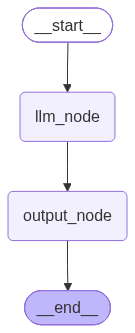

In [1]:
from pathlib import Path

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage, ToolMessage, SystemMessage
from langchain_openai import ChatOpenAI
import os

from rich import print as rprint
from random import randint
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)
class OverAllState(MessagesState):
    output: str

def llm_node(state: OverAllState) -> OverAllState:
    messages = state["messages"]
    res = model.invoke(messages)
    return {
        "messages": [res]
    }

def output_node(state: OverAllState) -> OverAllState:
    return {
        "output": state["messages"][-1].content
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("llm_node", llm_node)
builder.add_node("output_node", output_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", "output_node")
builder.add_edge("output_node", END)

# 定义并在编译时传递 Checkpointer
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

# 定义配置对象
config = {"configurable": {"thread_id": "chapter_tmp"}}
# 调用时传递
res=graph.invoke(
    {"messages": [HumanMessage("你好")]},
    config=config,
    durability="async" # sync / exit
)
print(res["output"])

print('=' * 30, '-> 完整消息列表 <-', '=' * 30)
for msg in res["messages"]:
    msg.pretty_print()

from IPython.display import display
display(graph)

## 6.4 查看历史检查点

**`LangGraph`** 在配置检查点存储器后，会把同一个 **`thread_id`** 下的执行过程保存为一组检查点。
可以通过对同组检查点进行回溯和失败恢复。

本节主要介绍两个常用方法：

* **`graph.get_state_history(config)`**：查看指定会话的完整历史检查点。
* **`graph.get_state(config)`**：查看指定会话的**最新**检查点，或者查看某个**指定** **`checkpoint_id`** 对应的检查点。

### 6.4.1. 查看完整历史检查点列表


2026-10-17 00:28:03.480 | INFO     | __main__:node_joke:43 - node_joke 已执行
2026-10-17 00:28:03.481 | INFO     | __main__:node_poem:34 - node_poem 已执行
2026-10-17 00:28:13.538 | INFO     | __main__:node_output:52 - node_output 已执行


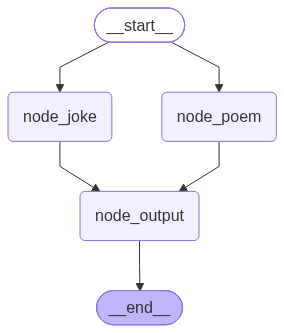

{
    'final_output': '关于 猫咪 的七言绝句：\n《猫》\n\n月照狸奴卧小窗，  \n尾摇灯影扑飞蛾。  \n一声轻唤回头顾，  
\n满院清风入梦来。\n笑话：\n猫咪为什么总觉得自己是老板？\n\n因为它每天都在提醒你：“铲屎官，开饭了！”'
}

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from loguru import logger
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)
# 没有继承Message
class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    final_output: str

class InputState(TypedDict):
    topic: str

class OutputState(TypedDict):
    final_output: str

def node_poem(state: InputState) -> OverAllState:
    logger.info(f"node_poem 已执行")
    topic = state["topic"]
    poem = model.invoke([HumanMessage(f"写一首关于 {topic} 的七言绝句")]).content

    return {
        "poem": poem
    }

def node_joke(state: InputState) -> OverAllState:
    logger.info(f"node_joke 已执行")
    topic = state["topic"]
    joke = model.invoke([HumanMessage(f"写一个关于 {topic} 的笑话")]).content

    return {
        "joke": joke
    }

def node_output(state: OverAllState) -> OutputState:
    logger.info("node_output 已执行")
    topic = state["topic"]
    poem = state["poem"]
    joke = state["joke"]
    final_output = f"关于 {topic} 的七言绝句：\n{poem}\n笑话：\n{joke}"

    return {
        "final_output": final_output
    }

builder = StateGraph(state_schema=OverAllState, input_schema=InputState, output_schema=OutputState)
builder.add_node("node_poem", node_poem)
builder.add_node("node_joke", node_joke)
builder.add_node("node_output", node_output)
builder.add_edge(START, "node_poem")
builder.add_edge(START, "node_joke")
builder.add_edge("node_poem", "node_output")
builder.add_edge("node_joke", "node_output")
builder.add_edge("node_output", END)

checkpointer = InMemorySaver()
config = {"configurable": {"thread_id": "123"}}
graph = builder.compile(checkpointer=checkpointer)
res = graph.invoke({"topic": "猫咪"}, config=config)

from IPython.display import display
display(graph)

rprint(res)

In [7]:
print('=' * 30, '-> 历史检查点列表 <-', '=' * 30)
history_checkpoints = list(graph.get_state_history(config=config))
for i in range(len(history_checkpoints)):
    print(f"第 {i} 个历史检查点:")
    rprint(history_checkpoints[i])

============================== -> 历史检查点列表 <- ==============================
第 0 个历史检查点:


StateSnapshot(
    values={
        'topic': '猫咪',
        'poem': '《猫》\n\n月照狸奴卧小窗，  \n尾摇灯影扑飞蛾。  \n一声轻唤回头顾，  \n满院清风入梦来。',
        'joke': '猫咪为什么总觉得自己是老板？\n\n因为它每天都在提醒你：“铲屎官，开饭了！”',
        'final_output': '关于 猫咪 的七言绝句：\n《猫》\n\n月照狸奴卧小窗，  \n尾摇灯影扑飞蛾。  \n一声轻唤回头顾，
\n满院清风入梦来。\n笑话：\n猫咪为什么总觉得自己是老板？\n\n因为它每天都在提醒你：“铲屎官，开饭了！”'
    },
    next=(),
    config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1c9fc4-ff20-6e0a-8002-56be674657d0'
        }
    },
    metadata={'source': 'loop', 'step': 2, 'parents': {}},
    created_at='2026-10-17T07:28:13.540088+00:00',
    parent_config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1c9fc4-ff1b-6d60-8001-4ac0a270e5ed'
        }
    },
    tasks=(),
    interrupts=()
)

第 1 个历史检查点:


StateSnapshot(
    values={
        'topic': '猫咪',
        'poem': '《猫》\n\n月照狸奴卧小窗，  \n尾摇灯影扑飞蛾。  \n一声轻唤回头顾，  \n满院清风入梦来。',
        'joke': '猫咪为什么总觉得自己是老板？\n\n因为它每天都在提醒你：“铲屎官，开饭了！”'
    },
    next=('node_output',),
    config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1c9fc4-ff1b-6d60-8001-4ac0a270e5ed'
        }
    },
    metadata={'source': 'loop', 'step': 1, 'parents': {}},
    created_at='2026-10-17T07:28:13.538020+00:00',
    parent_config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1c9fc4-9f2f-63e8-8000-975d015f7eab'
        }
    },
    tasks=(
        PregelTask(
            id='353b4df6-dd03-a1f9-ea9b-c428f77f7c8d',
            name='node_output',
            path=('__pregel_pull', 'node_output'),
            error=None,
            interrupts=(),
            state=None,
            result={
                'final_output': '关于 猫咪 的七言绝句：\n《猫》\n\n月照狸奴卧小窗，  \n尾摇灯影扑飞蛾。  
\n一声轻唤回头顾，  
\n满院清风入梦来。\n笑话：\n猫咪为什么总觉得自己是老板？\n\n因为它每天都在提醒你：“铲屎官，开饭了！”'
            }
        ),
    ),
    interrupts=()
)

第 2 个历史检查点:


StateSnapshot(
    values={'topic': '猫咪'},
    next=('node_poem', 'node_joke'),
    config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1c9fc4-9f2f-63e8-8000-975d015f7eab'
        }
    },
    metadata={'source': 'loop', 'step': 0, 'parents': {}},
    created_at='2026-10-17T07:28:03.479643+00:00',
    parent_config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1c9fc4-9f2e-60e2-bfff-fb805c5b78bd'
        }
    },
    tasks=(
        PregelTask(
            id='ce3c8bc3-2fd9-58e9-63b3-7db6ac580f37',
            name='node_poem',
            path=('__pregel_pull', 'node_poem'),
            error=None,
            interrupts=(),
            state=None,
            result={
                'poem': '《猫》\n\n月照狸奴卧小窗，  \n尾摇灯影扑飞蛾。  \n一声轻唤回头顾，  \n满院清风入梦来。'
            }
        ),
        PregelTask(
            id='97d53f2c-d86e-a753-2001-93530fd6414e',
            name='node_joke',
            path=('__pregel_pull', 'node_joke'),
            error=None,
            interrupts=(),
            state=None,
            result={'joke': '猫咪为什么总觉得自己是老板？\n\n因为它每天都在提醒你：“铲屎官，开饭了！”'}
        )
    ),
    interrupts=()
)

第 3 个历史检查点:


StateSnapshot(
    values={},
    next=('__start__',),
    config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1c9fc4-9f2e-60e2-bfff-fb805c5b78bd'
        }
    },
    metadata={'source': 'input', 'step': -1, 'parents': {}},
    created_at='2026-10-17T07:28:03.479158+00:00',
    parent_config=None,
    tasks=(
        PregelTask(
            id='41acf66a-f0af-5d1d-e04d-628b99be267b',
            name='__start__',
            path=('__pregel_pull', '__start__'),
            error=None,
            interrupts=(),
            state=None,
            result={'topic': '猫咪'}
        ),
    ),
    interrupts=()
)

### 6.4.2 StateSnapshot

源代码:
```python
class StateSnapshot(NamedTuple):
    """Snapshot of the state of the graph at the beginning of a step."""

    values: dict[str, Any] | Any
    """Current values of channels."""
    next: tuple[str, ...]
    """The name of the node to execute in each task for this step."""
    config: RunnableConfig
    """Config used to fetch this snapshot."""
    metadata: CheckpointMetadata | None
    """Metadata associated with this snapshot."""
    created_at: str | None
    """Timestamp of snapshot creation."""
    parent_config: RunnableConfig | None
    """Config used to fetch the parent snapshot, if any."""
    tasks: tuple[PregelTask, ...]
    """Tasks to execute in this step. If already attempted, may contain an error."""
    interrupts: tuple[Interrupt, ...]
    """Interrupts that occurred in this step.

    When reading the latest state (`get_state` without a `checkpoint_id`), this
    contains only interrupts still waiting for an answer. When reading a specific
    checkpoint or state history, it contains the most recent interrupt each task
    raised in that step, including ones answered later in the same step.
    """
```

教程里对字段已经有比较详细的说明。包括字段含义。下面包括一些没有说明的类或字段

```python
class PregelTask(NamedTuple):
    """A Pregel task."""

    id: str
    name: str
    path: tuple[str | int | tuple, ...]
    error: Exception | None = None
    interrupts: tuple[Interrupt, ...] = ()
    state: None | RunnableConfig | StateSnapshot = None
    result: Any | None = None

```


### 6.4.3 查看最新检查点

可以使用`get_state`查询最新检查点

```python
latest_history_checkpoint = graph.get_state(config=config)
print(latest_history_checkpoint)
```


2026-10-17 01:17:56.849 | INFO     | __main__:node_joke:43 - node_joke 已执行
2026-10-17 01:17:56.849 | INFO     | __main__:node_poem:34 - node_poem 已执行
2026-10-17 01:18:21.967 | INFO     | __main__:node_output:52 - node_output 已执行


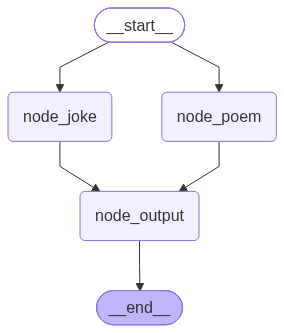

StateSnapshot(
    values={
        'topic': '猫咪',
        'poem': '**《猫咪》**\n\n懒卧春窗晒暖阳，  \n轻摇长尾戏花香。  \n夜来踏月寻鱼影，  \n一声娇喵入梦乡。',
        'joke': '猫咪为什么总爱坐在电脑旁边？\n\n因为它想当“网红”——每天都在“上网”，还顺便踩踩键盘！ 😺',
        'final_output': '关于 猫咪 的七言绝句：\n**《猫咪》**\n\n懒卧春窗晒暖阳，  \n轻摇长尾戏花香。  
\n夜来踏月寻鱼影，  
\n一声娇喵入梦乡。\n笑话：\n猫咪为什么总爱坐在电脑旁边？\n\n因为它想当“网红”——每天都在“上网”，还顺便踩踩键盘！ 😺'
    },
    next=(),
    config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1ca035-11bd-6296-8002-a46ba051de7d'
        }
    },
    metadata={'source': 'loop', 'step': 2, 'parents': {}},
    created_at='2026-10-17T08:18:21.968648+00:00',
    parent_config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1ca035-11b8-6dfe-8001-203e1ef01f98'
        }
    },
    tasks=(),
    interrupts=()
)

In [8]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from loguru import logger
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)
# 没有继承Message
class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    final_output: str

class InputState(TypedDict):
    topic: str

class OutputState(TypedDict):
    final_output: str

def node_poem(state: InputState) -> OverAllState:
    logger.info(f"node_poem 已执行")
    topic = state["topic"]
    poem = model.invoke([HumanMessage(f"写一首关于 {topic} 的七言绝句")]).content

    return {
        "poem": poem
    }

def node_joke(state: InputState) -> OverAllState:
    logger.info(f"node_joke 已执行")
    topic = state["topic"]
    joke = model.invoke([HumanMessage(f"写一个关于 {topic} 的笑话")]).content

    return {
        "joke": joke
    }

def node_output(state: OverAllState) -> OutputState:
    logger.info("node_output 已执行")
    topic = state["topic"]
    poem = state["poem"]
    joke = state["joke"]
    final_output = f"关于 {topic} 的七言绝句：\n{poem}\n笑话：\n{joke}"

    return {
        "final_output": final_output
    }

builder = StateGraph(state_schema=OverAllState, input_schema=InputState, output_schema=OutputState)
builder.add_node("node_poem", node_poem)
builder.add_node("node_joke", node_joke)
builder.add_node("node_output", node_output)
builder.add_edge(START, "node_poem")
builder.add_edge(START, "node_joke")
builder.add_edge("node_poem", "node_output")
builder.add_edge("node_joke", "node_output")
builder.add_edge("node_output", END)

checkpointer = InMemorySaver()
config = {"configurable": {"thread_id": "123"}}
graph = builder.compile(checkpointer=checkpointer)
res = graph.invoke({"topic": "猫咪"}, config=config)

from IPython.display import display
display(graph)

rprint(graph.get_state(config=config))

### 6.4.4 根据ID查看指定检查点
如果希望查看某个历史检查点，可以在 **`configurable`** 中额外传入 **`checkpoint_id`**：

```python
target_config = {
    "configurable": {
        "thread_id": "123",
        "checkpoint_id": "某个历史 checkpoint_id"
    }
}

snapshot = graph.get_state(config=target_config)
print(snapshot)
```

2026-10-17 01:28:57.997 | INFO     | __main__:node_joke:43 - node_joke 已执行
2026-10-17 01:28:57.998 | INFO     | __main__:node_poem:34 - node_poem 已执行
2026-10-17 01:29:53.897 | INFO     | __main__:node_output:52 - node_output 已执行


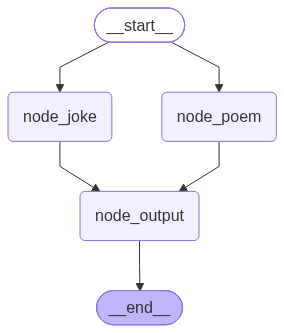

============================== -> 历史检查点列表 <- ==============================
第 0 个历史检查点:


StateSnapshot(
    values={
        'topic': '猫咪',
        'poem': '月照窗前猫影长，  \n轻摇尾尖戏晚霜。  \n偷衔一缕清风去，  \n留得铃声入梦乡。',
        'joke': '猫咪为什么总爱盯着电脑看？\n\n因为它想抓住鼠标！',
        'final_output': '关于 猫咪 的七言绝句：\n月照窗前猫影长，  \n轻摇尾尖戏晚霜。  \n偷衔一缕清风去，  
\n留得铃声入梦乡。\n笑话：\n猫咪为什么总爱盯着电脑看？\n\n因为它想抓住鼠标！'
    },
    next=(),
    config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1ca04e-d87e-69a2-8002-b5fba765407c'
        }
    },
    metadata={'source': 'loop', 'step': 2, 'parents': {}},
    created_at='2026-10-17T08:29:53.898325+00:00',
    parent_config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1ca04e-d87a-6488-8001-9cd7f058ff75'
        }
    },
    tasks=(),
    interrupts=()
)

第 1 个历史检查点:


StateSnapshot(
    values={
        'topic': '猫咪',
        'poem': '月照窗前猫影长，  \n轻摇尾尖戏晚霜。  \n偷衔一缕清风去，  \n留得铃声入梦乡。',
        'joke': '猫咪为什么总爱盯着电脑看？\n\n因为它想抓住鼠标！'
    },
    next=('node_output',),
    config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1ca04e-d87a-6488-8001-9cd7f058ff75'
        }
    },
    metadata={'source': 'loop', 'step': 1, 'parents': {}},
    created_at='2026-10-17T08:29:53.896552+00:00',
    parent_config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1ca04c-c360-687e-8000-7608c9600d44'
        }
    },
    tasks=(
        PregelTask(
            id='72a87546-3ccc-dfd9-1628-23e9bad878e7',
            name='node_output',
            path=('__pregel_pull', 'node_output'),
            error=None,
            interrupts=(),
            state=None,
            result={
                'final_output': '关于 猫咪 的七言绝句：\n月照窗前猫影长，  \n轻摇尾尖戏晚霜。  \n偷衔一缕清风去，  
\n留得铃声入梦乡。\n笑话：\n猫咪为什么总爱盯着电脑看？\n\n因为它想抓住鼠标！'
            }
        ),
    ),
    interrupts=()
)

第 2 个历史检查点:


StateSnapshot(
    values={'topic': '猫咪'},
    next=('node_poem', 'node_joke'),
    config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1ca04c-c360-687e-8000-7608c9600d44'
        }
    },
    metadata={'source': 'loop', 'step': 0, 'parents': {}},
    created_at='2026-10-17T08:28:57.996909+00:00',
    parent_config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1ca04c-c35f-6370-bfff-4463453b3b73'
        }
    },
    tasks=(
        PregelTask(
            id='af728387-78d3-2cf0-f11c-7cfcce9d6a96',
            name='node_poem',
            path=('__pregel_pull', 'node_poem'),
            error=None,
            interrupts=(),
            state=None,
            result={'poem': '月照窗前猫影长，  \n轻摇尾尖戏晚霜。  \n偷衔一缕清风去，  \n留得铃声入梦乡。'}
        ),
        PregelTask(
            id='84ac5166-9e89-fead-75e1-044dc94f8cd3',
            name='node_joke',
            path=('__pregel_pull', 'node_joke'),
            error=None,
            interrupts=(),
            state=None,
            result={'joke': '猫咪为什么总爱盯着电脑看？\n\n因为它想抓住鼠标！'}
        )
    ),
    interrupts=()
)

第 3 个历史检查点:


StateSnapshot(
    values={},
    next=('__start__',),
    config={
        'configurable': {
            'thread_id': '123',
            'checkpoint_ns': '',
            'checkpoint_id': '1f1ca04c-c35f-6370-bfff-4463453b3b73'
        }
    },
    metadata={'source': 'input', 'step': -1, 'parents': {}},
    created_at='2026-10-17T08:28:57.996372+00:00',
    parent_config=None,
    tasks=(
        PregelTask(
            id='d18ed56b-c7a8-65f1-1fad-25f2c3b6708e',
            name='__start__',
            path=('__pregel_pull', '__start__'),
            error=None,
            interrupts=(),
            state=None,
            result={'topic': '猫咪'}
        ),
    ),
    interrupts=()
)

In [9]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from loguru import logger
from dotenv import load_dotenv
# 从.env文件中加载环境变量
load_dotenv(override=True, verbose=True,dotenv_path="/Users/skk/Developer/lang-chain-learn/conf/.env")

OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]
OPENAI_API_BASE = os.environ["OPENAI_API_BASE"]  # 与本项目 .env 中的名称一致

model = ChatOpenAI(
    model="gpt-6-luna",  # 当前配置已验证可用；原 gpt-5.5 返回模型权限 403
    api_key=OPENAI_API_KEY,
    base_url=OPENAI_API_BASE,
)
# 没有继承Message
class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    final_output: str

class InputState(TypedDict):
    topic: str

class OutputState(TypedDict):
    final_output: str

def node_poem(state: InputState) -> OverAllState:
    logger.info(f"node_poem 已执行")
    topic = state["topic"]
    poem = model.invoke([HumanMessage(f"写一首关于 {topic} 的七言绝句")]).content

    return {
        "poem": poem
    }

def node_joke(state: InputState) -> OverAllState:
    logger.info(f"node_joke 已执行")
    topic = state["topic"]
    joke = model.invoke([HumanMessage(f"写一个关于 {topic} 的笑话")]).content

    return {
        "joke": joke
    }

def node_output(state: OverAllState) -> OutputState:
    logger.info("node_output 已执行")
    topic = state["topic"]
    poem = state["poem"]
    joke = state["joke"]
    final_output = f"关于 {topic} 的七言绝句：\n{poem}\n笑话：\n{joke}"

    return {
        "final_output": final_output
    }

builder = StateGraph(state_schema=OverAllState, input_schema=InputState, output_schema=OutputState)
builder.add_node("node_poem", node_poem)
builder.add_node("node_joke", node_joke)
builder.add_node("node_output", node_output)
builder.add_edge(START, "node_poem")
builder.add_edge(START, "node_joke")
builder.add_edge("node_poem", "node_output")
builder.add_edge("node_joke", "node_output")
builder.add_edge("node_output", END)

checkpointer = InMemorySaver()
config = {"configurable": {"thread_id": "123"}}
graph = builder.compile(checkpointer=checkpointer)
res = graph.invoke({"topic": "猫咪"}, config=config)

from IPython.display import display
display(graph)
print('=' * 30, '-> 历史检查点列表 <-', '=' * 30)
history_checkpoints = list(graph.get_state_history(config=config))
for i in range(len(history_checkpoints)):
    print(f"第 {i} 个历史检查点:")
    rprint(history_checkpoints[i])

In [11]:
print('=' * 30, '-> 根据ID查看特定检查点 <-', '=' * 30)
checkpointe_id = history_checkpoints[3].config["configurable"]["checkpoint_id"]
print(f"checkpointe_id: {checkpointe_id}")

target_config = {
    "configurable": {
        "thread_id": config["configurable"]["thread_id"],
        "checkpoint_id": checkpointe_id
    }
}

specific_history_checkpoint = graph.get_state(config=target_config)
rprint(specific_history_checkpoint)

============================== -> 根据ID查看特定检查点 <- ==============================
checkpointe_id: 1f1ca04c-c35f-6370-bfff-4463453b3b73


StateSnapshot(
    values={},
    next=('__start__',),
    config={'configurable': {'thread_id': '123', 'checkpoint_id': '1f1ca04c-c35f-6370-bfff-4463453b3b73'}},
    metadata={'source': 'input', 'step': -1, 'parents': {}},
    created_at='2026-10-17T08:28:57.996372+00:00',
    parent_config=None,
    tasks=(
        PregelTask(
            id='d18ed56b-c7a8-65f1-1fad-25f2c3b6708e',
            name='__start__',
            path=('__pregel_pull', '__start__'),
            error=None,
            interrupts=(),
            state=None,
            result={'topic': '猫咪'}
        ),
    ),
    interrupts=()
)

当前场景下，我们已经获取了完整检查点列表，然后从中取了某个检查点的 **`checkpoint_id`**，然后调用 **`get_state()`** 查到了它对应的快照。

这看起来有些“绕”，因为我们本来就已经拿到了完整的历史快照。但在实际场景中，这个方法仍然很有意义。

例如，在后续的 **检查点回溯-分叉** 场景中，我们经常会基于历史检查点创建新的检查点，拿到该检查点的、带有 **`checkpoint_id`** 的配置信息 **`config`**。此时就可以将 **`config`** 传递给 **`graph.get_state()`**，从而便捷而精确地查看该检查点的快照。

# 总结

1. 如何启用可恢复执行？
* 使用检查点存储（内存或者基于数据库）
* 模型调用时使用相同的 `thread_id` 配置

2. 如何配置持久化模式？

* 在 `invoke`函数使用`durability`参数

3. 如何查看历史检查点？
4. 如何利用检查点进行恢复、回放和分叉？

# 问题

### 1. 为什么使用 PostgreSQL 实现长短期记忆，而不是 MySQL？

**MySQL 也能实现。选型主要取决于存储、检索需求和适配成本。**

先区分记忆的作用范围：

| 类型 | 保存内容 | 作用范围 | PostgreSQL 实现 |
| --- | --- | --- | --- |
| 短期记忆 | 消息历史、图状态、执行进度 | 同一个 `thread_id` | `PostgresSaver` |
| 长期记忆 | 用户偏好、事实、共享知识 | 可以跨会话 | `PostgresStore` |

“长短期”主要描述作用范围和使用方式；检查点即使保存一年，也仍属于会话级短期记忆。

**仅保存检查点，MySQL 的 InnoDB 同样具备事务、索引和崩溃恢复能力。** PostgreSQL 的便利在于可以把检查点、结构化记忆和语义检索放在同一个数据库中处理，且 LangGraph 提供了现成的官方适配。

例如，一条长期记忆可以是：

```json
{"user_id": "u001", "fact": "用户是素食者", "category": "饮食偏好"}
```

既可以按用户和类别精确筛选，也可以将文本转为向量，根据“晚餐推荐”检索相关记忆。PostgreSQL 的 JSONB、索引与 `pgvector` 扩展便于组合这些查询；`PostgresStore` 的向量检索是可选能力，普通检查点不需要它。

**工程取舍：** 新项目同时需要上述能力时，PostgreSQL 是方便的默认选择；已有 MySQL、只需保存会话状态时，没有必要仅为检查点另引入 PostgreSQL。MySQL 也有 JSON 能力和社区检查点适配器，但需要核对版本及功能支持，不能直接替换 `PostgresSaver` 的连接地址。

### 2. 在持久化模式小节，为什么 `async` 的容灾能力比 `sync` 弱？

**关键是进入下一个超步前，是否等待当前检查点保存成功。** `async` 允许执行进度领先于持久化进度，存在“已经算完，但尚未保存完成”的窗口。

假设 `A → B → C` 各占一个超步：

```text
async：A 完成 → 后台保存 A 后的检查点，同时开始 B
              → 若进程此时崩溃，A 后的检查点可能尚未保存成功

sync： A 完成 → 等待 A 后的检查点保存成功 → 才开始 B
```

`async` 在恢复时可能需要从更早的位置继续，重复部分计算；已保存的任务中间结果仍可能被复用。`sync` 则保证开始 B 前，A 后的检查点已写入成功，但增加了等待时间。

因此，`async` 通过重叠计算和写入降低延迟，`sync` 通过等待缩小未保存进度的窗口。写入越慢、重复计算代价越高，这个取舍越明显。

`sync` 也不保证节点内部操作只执行一次：例如外部扣款已成功，但节点返回、保存检查点前崩溃，恢复后仍可能再次调用扣款接口。此类操作还需要幂等设计。

**补充：节点报错会导致异步检查点保存失败吗？**

普通 Python 异常通常仍会经过退出清理、等待后台写入，节点报错本身不会必然导致检查点保存失败。进程被强杀、解释器崩溃或断电，则可能让尚未完成的写入丢失。

本地验证：使用 `SqliteSaver` 和 `durability="async"`，A 成功、B 抛出异常后，重新连接数据库仍能读到 A 的结果，待执行节点是 B。

注意：6.3 示例使用 `InMemorySaver`，进程退出后两种模式的数据都会丢失。观察跨进程恢复需要 SQLite、PostgreSQL 等持久化后端；`sync` 的保障也取决于后端本身的持久性。